# P1 – Network and Louvain communities (fixed version)

Fixes compared with the first notebook:
1. all memberships kept: the `role` column is scrambled in this dataset, so it cannot be used to filter
2. agreed country list (no Turkey; Ukraine, Moldova, Western Balkans added)
3. Newman weight uses the full consortium size
4. CSVs read with `skipinitialspace` and `escapechar`
5. no connected-components consensus: best of 20 Louvain runs + stability

In [ ]:
# Imports
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import normalized_mutual_info_score as nmi
from sklearn.metrics import adjusted_mutual_info_score as ami

import networkx as nx
import community as community_louvain
from ANS_06_utils import graph_summary
import pyfixest as pf

from scipy.stats import chi2_contingency
import plotly.express as px


In [37]:
# 1. Load the data
# Netzschleuder CSVs have spaces after the commas and escaped quotes inside names
df_nodes = pd.read_csv("horizon_europe/nodes.csv", skipinitialspace=True, escapechar="\\", low_memory=False)
df_edges = pd.read_csv("horizon_europe/edges.csv", skipinitialspace=True, escapechar="\\")
df_nodes.columns = [c.lstrip("#").strip() for c in df_nodes.columns]   # '# index' -> 'index'
df_edges.columns = [c.lstrip("#").strip() for c in df_edges.columns]   # '# source' -> 'source'
# in edges.csv: source = organization, target = project

In [38]:
df_nodes.head()

,index,is_project,name,id,latitude,longitude,euroscivoc,acronym,status,start_date,...,grant_doi,keywords,sme,activity_type,city,post_code,country,nuts_code,url,_pos
0,0,1,Full spectrum SOLar Direct Air Capture & conve...,101069359,NaN,NaN,natural sciences/chemical sciences/electrochem...,SolDAC,SIGNED,1661990400,...,10.3030/101069359,"zero-carbon, solar energy, air mining, Negativ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-22.19285885, 116.25605589])"
1,1,1,Artificial PHOTOsynthesis to produce FUELs and...,101069357,NaN,NaN,engineering and technology/environmental engin...,Photo2Fuel,SIGNED,1661990400,...,10.3030/101069357,solar energy; bacteria; archaea; solar fuels; ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-23.54534475, 117.30806949])"
2,2,1,Bridging Organizations and marginalized commun...,101069586,NaN,NaN,social sciences/sociology/governance|social sc...,BOLSTER,SIGNED,1661990400,...,10.3030/101069586,Transition strategies; Participation; Marginal...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-18.23962287, 118.80845353])"
3,3,1,NCPS NETwork for the GREEN transition in clima...,101069604,NaN,NaN,NaN,GREENET,SIGNED,1656633600,...,10.3030/101069604,"Competence development, Capacity building, CL5...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-27.77547463, 109.60801029])"
4,4,1,"Social Sciences and Humanities for Climate, En...",101069529,NaN,NaN,social sciences/economics and business/economi...,SSH CENTRE,SIGNED,1661990400,...,10.3030/101069529,Transitions; Transdisciplinary; Epistemic cult...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-26.48000805, 108.76182656])"


In [39]:
# 2. Filters
EU27 = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "EL", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"]
european_countries = EU27 + ["NO", "IS", "LI", "CH", "UK",            # EFTA + UK
                             "AL", "BA", "ME", "MK", "RS", "XK",      # Western Balkans
                             "UA", "MD", "FO", "VA", "MC", "GI"]      # other European
valid_funding_schemes = ["HORIZON-RIA", "HORIZON-IA", "HORIZON-JU-RIA", "HORIZON-JU-IA"]
valid_activity_types = ["HES", "REC"]

projects = df_nodes[(df_nodes["is_project"] == 1)
                    & df_nodes["funding_scheme"].isin(valid_funding_schemes)]
orgs = df_nodes[(df_nodes["is_project"] == 0)
                & df_nodes["activity_type"].isin(valid_activity_types)
                & df_nodes["country"].isin(european_countries)]

# all members of the kept projects (all organization types and countries)
# no role filter: the role labels are scrambled (e.g. 76% of "associated partners" receive EU money)
memberships = df_edges[df_edges["target"].isin(projects["index"])]

# Newman weight needs the real consortium size: all members of the project
consortium_size = memberships.groupby("target")["source"].nunique()

# keep European universities and research organizations with at least 3 projects
memberships = memberships[memberships["source"].isin(orgs["index"])]
n_projects = memberships.groupby("source")["target"].nunique()
final_org_ids = set(n_projects[n_projects >= 3].index)
memberships = memberships[memberships["source"].isin(final_org_ids)]

print(f"Organizations: {len(final_org_ids)}, projects: {memberships['target'].nunique()}")

Organizations: 1890, projects: 4906


In [40]:
# 3. Newman-weighted projection: each project adds 1/(n-1) to every pair of its members
org_net = nx.Graph()
for project, members in memberships.groupby("target")["source"]:
    members = sorted(set(members))
    if len(members) < 2:                    # a project with one kept member adds no edge
        continue
    w = 1.0 / (consortium_size[project] - 1)
    for u, v in itertools.combinations(members, 2):
        if org_net.has_edge(u, v):
            org_net[u][v]["weight"] += w
            org_net[u][v]["n_joint"] += 1
        else:
            org_net.add_edge(u, v, weight=w, n_joint=1)

for u, v, d in org_net.edges(data=True):
    d["dist"] = 1.0 / d["weight"]          # distance for betweenness (P2)

graph_summary(org_net)

Directed: False
Weighted: True
Nodes: 1890
Edges: 105855
Density: 0.0592990328300016
Number of components: 1


In [41]:
# 4. Node labels: name, country, type, projects, coordinated projects, topic
def second_level_fields(s):
    """'natural sciences/chemical sciences/electrochemistry|...' -> ['natural sciences', ...]"""
    if not isinstance(s, str):
        return []
    return list({x.split("/")[1] for x in s.split("|") if x.count("/") >= 1})


project_fields = projects.set_index("index")["euroscivoc"].apply(second_level_fields)
fields_long = memberships.assign(field=memberships["target"].map(project_fields)).explode("field")
topic = fields_long.dropna(subset=["field"]).groupby("source")["field"].agg(lambda s: s.mode()[0])
# coordinator = the first organization of the project (order == 1); the role column is unreliable
n_coord = memberships[memberships["order"] == 1].groupby("source").size()

info = orgs.set_index("index")
labels = pd.DataFrame({
    "name": info["name"],
    "country": info["country"],
    "org_type": info["activity_type"],
    "n_projects": n_projects,
    "n_coordinated": n_coord,
    "topic": topic,
}).loc[list(org_net.nodes())]
labels["n_coordinated"] = labels["n_coordinated"].fillna(0).astype(int)
labels["topic"] = labels["topic"].fillna("unknown")
nx.set_node_attributes(org_net, labels.to_dict("index"))
labels.head()

,name,country,org_type,n_projects,n_coordinated,topic
23955,EUROPEAN INNOVATION MARKETPLACE ASBL,BE,REC,6.0,0,computer and information sciences
23957,THE UNIVERSITY COURT OF THE UNIVERSITY OF ST A...,UK,HES,15.0,1,biological sciences
23958,FUNDACIO INSTITUT DE RECERCA EN ENERGIA DE CAT...,ES,REC,37.0,8,environmental engineering
23959,UNIVERSIDAD DE LLEIDA,ES,HES,12.0,2,environmental engineering
23960,CONSIGLIO NAZIONALE DELLE RICERCHE,IT,REC,311.0,31,computer and information sciences


In [42]:
# 5. Louvain: 20 runs, keep the one with the highest modularity
runs = [community_louvain.best_partition(org_net, weight="weight", random_state=s) for s in range(20)]
Q = [community_louvain.modularity(r, org_net, weight="weight") for r in runs]
best_seed = int(np.argmax(Q))
partition = runs[best_seed]
labels["community"] = pd.Series(partition)

print(f"Best run: seed {best_seed}, {len(set(partition.values()))} communities, Q = {Q[best_seed]:.4f}")
print(f"Modularity over 20 runs: mean {np.mean(Q):.4f}, min {min(Q):.4f}, max {max(Q):.4f}")

Best run: seed 3, 4 communities, Q = 0.2426
Modularity over 20 runs: mean 0.2408, min 0.2358, max 0.2426


In [43]:
# 6. Stability: compare all pairs of runs
nodes_sorted = sorted(org_net.nodes())
vecs = [[r[n] for n in nodes_sorted] for r in runs]
pairs = list(itertools.combinations(vecs, 2))
print(f"Mean NMI between runs: {np.mean([nmi(a, b) for a, b in pairs]):.3f}")
print(f"Mean AMI between runs: {np.mean([ami(a, b) for a, b in pairs]):.3f}")

Mean NMI between runs: 0.754
Mean AMI between runs: 0.754


In [44]:
# 7. Resolution sweep (robustness): 10 runs per resolution
rows = []
for res in [0.5, 0.75, 1.0, 1.25, 1.5]:
    rr = [community_louvain.best_partition(org_net, weight="weight", resolution=res, random_state=s)
          for s in range(10)]
    vv = [[r[n] for n in nodes_sorted] for r in rr]
    rows.append({
        "resolution": res,
        "communities (median)": int(np.median([len(set(r.values())) for r in rr])),
        "modularity (mean)": round(np.mean([community_louvain.modularity(r, org_net) for r in rr]), 3),
        "stability AMI": round(np.mean([ami(a, b) for a, b in itertools.combinations(vv, 2)]), 3),
    })
sweep = pd.DataFrame(rows)
sweep

,resolution,communities (median),modularity (mean),stability AMI
0,0.50,203,0.134,0.226
1,0.75,8,0.233,0.683
2,1.00,5,0.241,0.744
3,1.25,9,0.226,0.738
4,1.50,19,0.202,0.664


In [45]:
# 8. Community profiles: size, top topics, top countries
profiles = []
for c, grp in labels.groupby("community"):
    top_topics = grp["topic"].value_counts(normalize=True).head(3)
    top_countries = grp["country"].value_counts(normalize=True).head(3)
    profiles.append({
        "community": c,
        "size": len(grp),
        "top topics": ", ".join(f"{t} {v:.0%}" for t, v in top_topics.items()),
        "top countries": ", ".join(f"{t} {v:.0%}" for t, v in top_countries.items()),
        "n countries": grp["country"].nunique(),
    })
profiles = pd.DataFrame(profiles).sort_values("size", ascending=False)
profiles

,community,size,top topics,top countries,n countries
0,0,643,"computer and information sciences 30%, environ...","ES 16%, DE 12%, IT 8%",32
2,2,550,"clinical medicine 23%, computer and informatio...","DE 13%, ES 12%, UK 9%",35
3,3,396,"agriculture, forestry, and fisheries 38%, eart...","DE 13%, ES 12%, IT 8%",33
1,1,301,"earth and related environmental sciences 27%, ...","FR 18%, DE 12%, IT 9%",32


In [46]:
# 9. What organizes the communities? AMI with topic / country / type vs shuffled labels
rng = np.random.default_rng(0)
comm = labels["community"].values
rows = []
for col in ["topic", "country", "org_type"]:
    lab = labels[col].values
    real = ami(lab, comm) # maybe we should reason why don't we use NMI
    shuffled = [ami(rng.permutation(lab), comm) for _ in range(200)]
    rows.append({"label": col, "AMI": round(real, 3),
                 "shuffled mean": round(np.mean(shuffled), 4),
                 "shuffled 99th pct": round(np.percentile(shuffled, 99), 4)})
organizing = pd.DataFrame(rows)
organizing         

,label,AMI,shuffled mean,shuffled 99th pct
0,topic,0.202,-0.0002,0.0038
1,country,0.011,0.0000,0.0036
2,org_type,0.006,0.0000,0.0023


In [47]:
# 10. Niche communities: Louvain again inside each big community
niche = {}
for c, grp in labels.groupby("community"):
    sub = org_net.subgraph(grp.index)
    if sub.number_of_edges() == 0:
        niche.update({n: f"{c}.0" for n in grp.index})
        continue
    p = community_louvain.best_partition(sub, weight="weight", random_state=0)
    niche.update({n: f"{c}.{k}" for n, k in p.items()})
labels["niche"] = pd.Series(niche)
print(f"{labels['niche'].nunique()} niche communities")

24 niche communities


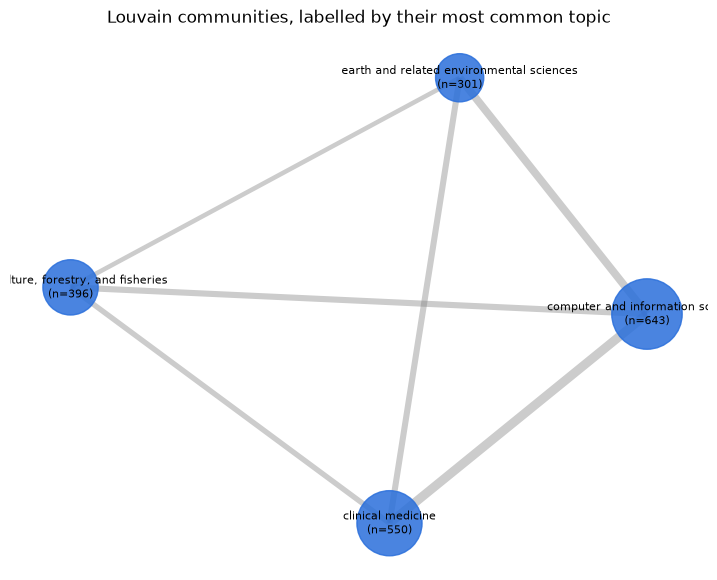

In [48]:
# 11. Figure: one node per community (instead of the full hairball)
C = nx.Graph()
for c, grp in labels.groupby("community"):
    if len(grp) >= 10:                      # skip tiny communities
        C.add_node(c, size=len(grp), topic=grp["topic"].value_counts().index[0])
for u, v, d in org_net.edges(data=True):
    cu, cv = partition[u], partition[v]
    if cu != cv and cu in C and cv in C:
        old = C[cu][cv]["weight"] if C.has_edge(cu, cv) else 0
        C.add_edge(cu, cv, weight=old + d["weight"])

pos = nx.spring_layout(C, weight="weight", seed=1)
wmax = max(d["weight"] for _, _, d in C.edges(data=True))
plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(C, pos, width=[0.5 + 6 * d["weight"] / wmax for _, _, d in C.edges(data=True)],
                       alpha=0.4, edge_color="gray")
nx.draw_networkx_nodes(C, pos, node_size=[4 * C.nodes[c]["size"] for c in C], node_color="#2a6fdb", alpha=0.85)
nx.draw_networkx_labels(C, pos, {c: f"{C.nodes[c]['topic']}\n(n={C.nodes[c]['size']})" for c in C}, font_size=8)
plt.title("Louvain communities, labelled by their most common topic")
plt.axis("off")
plt.show()

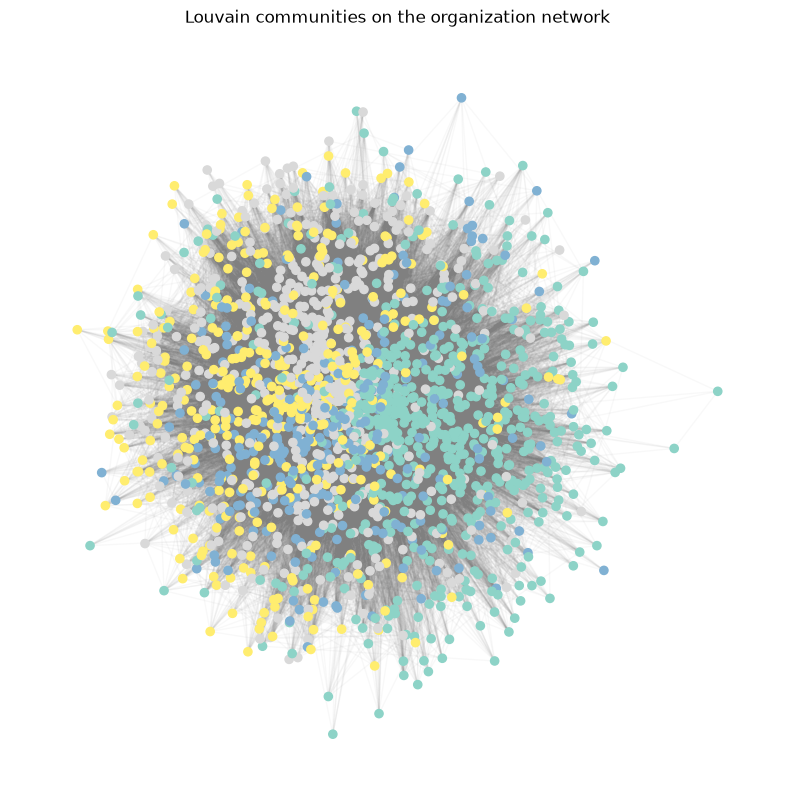

In [49]:
plt.figure(figsize=(10, 10))

pos_karate = nx.spring_layout(org_net, k=0.5, seed=2)

nx.draw_networkx_edges(org_net, pos_karate, alpha=0.05, edge_color="gray")
nx.draw_networkx_nodes(
    org_net,
    pos_karate,
    node_size=35,
    node_color=[partition[n] for n in org_net.nodes()],
    cmap=plt.cm.Set3,
)

plt.title("Louvain communities on the organization network")
plt.axis("off") 
plt.show()

**EU funding per organization**

In [50]:
labels["funding_eur"] = memberships.groupby("source")["ec_contribution"].sum()
labels.loc[labels["country"].isin(["CH", "UK"]), "funding_eur"] = np.nan   # missing, not zero
labels["funding_eur"].describe()

count    1.722000e+03
mean     9.755642e+06
std      2.872071e+07
min      0.000000e+00
25%      1.204824e+06
50%      2.647362e+06
75%      7.387248e+06
max      5.716925e+08
Name: funding_eur, dtype: float64

**Centrality measures**

Degree, strength, eigenvector, closeness

In [51]:
cent = pd.DataFrame(index=list(org_net.nodes()))

cent["degree"] = pd.Series(dict(org_net.degree())) 
cent["strength"] = pd.Series(dict(org_net.degree(weight="weight")))     # sum of tie weights
cent["eigenvector"] = pd.Series(nx.eigenvector_centrality_numpy(org_net, weight="weight"))
cent["closeness"] = pd.Series(nx.closeness_centrality(org_net, distance="dist"))
cent.describe()

,degree,strength,eigenvector,closeness
count,1890.000000,1890.000000,1890.000000,1890.000000
mean,112.015873,9.082707,0.010674,0.082135
std,130.560739,16.290110,0.020381,0.023222
min,4.000000,0.494949,0.000118,0.033054
25%,34.000000,1.986407,0.001998,0.064442
50%,62.000000,3.707653,0.004062,0.079177
75%,135.000000,8.951741,0.010013,0.097059
max,1080.000000,228.499696,0.290316,0.147255


**Betweenness**: how many shortest paths between other organizations go through this one. Paths are counted in steps (every tie = 1), so an organization only scores high if it links partners who don't work together directly.

In [52]:
cent["betweenness"] = pd.Series(nx.betweenness_centrality(org_net))   # unweighted: path length in steps
cent["betweenness"].describe()

count    1890.000000
mean        0.000534
std         0.002178
min         0.000000
25%         0.000010
50%         0.000035
75%         0.000200
max         0.045014
Name: betweenness, dtype: float64

Local clustering - do my partners know each other?
- 1 = all my partners work with each other (closed circle, no brokerage)
- 0 = none of my partners work with each other (I am the only link between them = broker)

In [53]:
cent["clustering"] = pd.Series(nx.clustering(org_net))
cent["clustering"].describe()

count    1890.000000
mean        0.502103
std         0.147015
min         0.115726
25%         0.396133
50%         0.494563
75%         0.601134
max         1.000000
Name: clustering, dtype: float64

How similar are the centralities? (Spearman = rank correlation)
Expectation: degree, strength and eigenvector are almost the same ranking (they all measure "size"). Betweenness should be the odd one out - it measures position, not size.

In [54]:
cent.corr(method="spearman").round(2)

,degree,strength,eigenvector,closeness,betweenness,clustering
degree,1.00,0.93,0.88,0.69,0.94,-0.67
strength,0.93,1.00,0.95,0.83,0.92,-0.76
eigenvector,0.88,0.95,1.00,0.88,0.85,-0.66
closeness,0.69,0.83,0.88,1.00,0.69,-0.60
betweenness,0.94,0.92,0.85,0.69,1.00,-0.84
clustering,-0.67,-0.76,-0.66,-0.60,-0.84,1.00


Top 10 for each measure

In [55]:
top10 = pd.DataFrame({
    col: labels.loc[cent[col].sort_values(ascending=False).head(10).index, "name"].str[:40].values
    for col in ["degree", "strength", "eigenvector", "betweenness"]
})
top10["lowest clustering"] = labels.loc[cent["clustering"].sort_values().head(10).index, "name"].str[:40].values
top10.index = range(1, 11)
top10

,degree,strength,eigenvector,betweenness,lowest clustering
1,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE
2,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE
3,CONSIGLIO NAZIONALE DELLE RICERCHE,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,CONSIGLIO NAZIONALE DELLE RICERCHE,CONSIGLIO NAZIONALE DELLE RICERCHE
4,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CONSIGLIO NAZIONALE DELLE RICERCHE,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF
5,KATHOLIEKE UNIVERSITEIT LEUVEN,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,CONSIGLIO NAZIONALE DELLE RICERCHE,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS
6,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,TEKNOLOGIAN TUTKIMUSKESKUS VTT OY,KATHOLIEKE UNIVERSITEIT LEUVEN,KATHOLIEKE UNIVERSITEIT LEUVEN
7,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,KATHOLIEKE UNIVERSITEIT LEUVEN,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,ALMA MATER STUDIORUM - UNIVERSITA DI BOL,ALMA MATER STUDIORUM - UNIVERSITA DI BOL
8,DANMARKS TEKNISKE UNIVERSITET,DEUTSCHES ZENTRUM FUR LUFT - UND RAUMFAH,DEUTSCHES ZENTRUM FUR LUFT - UND RAUMFAH,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,TECHNISCHE UNIVERSITEIT DELFT
9,AARHUS UNIVERSITET,DANMARKS TEKNISKE UNIVERSITET,DANMARKS TEKNISKE UNIVERSITET,AARHUS UNIVERSITET,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX
10,ALMA MATER STUDIORUM - UNIVERSITA DI BOL,TECHNISCHE UNIVERSITEIT DELFT,TECHNISCHE UNIVERSITEIT DELFT,DANMARKS TEKNISKE UNIVERSITET,POLITECNICO DI MILANO


**Giants and brokers**

- **Giants:** the 50 organizations with the most partners (highest degree).
- **Brokers:** organizations that sit on more shortest paths than their number of partners would predict. Big organizations are on many paths just because they have many partners, so we regress log(betweenness) on log(degree) and take the 50 largest residuals (organizations with ≥ 10 projects, since betweenness of very small ones is unstable).
- We don't control for coordination: in the projected network every project member is tied to all the others, so the coordinator has no special position.

log(betweenness) = b0 + b1·log(degree) + error

In [56]:
#Giants
data = labels.join(cent)
data["rank_degree"] = data["degree"].rank(ascending=False)
data["rank_betweenness"] = data["betweenness"].rank(ascending=False)
data["giant"] = data["rank_degree"] <= 50

In [77]:
# How concentrated is the network? Giants' share of organizations, memberships and EU funding
giant_ids = data.index[data["giant"]]
print(f"Giants: {data['giant'].mean():.1%} of organizations, "
      f"{memberships['source'].isin(giant_ids).mean():.1%} of memberships, "
      f"{data.loc[data['giant'], 'funding_eur'].sum() / data['funding_eur'].sum():.1%} of EU funding")

Giants: 2.6% of organizations, 24.4% of memberships, 30.3% of EU funding


In [57]:
#Brokers: regression residuals
data["coord_share"] = data["n_coordinated"] / data["n_projects"]
reg = data[data["n_projects"] >= 10].copy()

reg["log_betweenness"] = np.log(reg["betweenness"])     # all organizations with >= 10 projects have betweenness > 0
reg["log_degree"] = np.log(reg["degree"])

m1 = pf.feols("log_betweenness ~ log_degree", data=reg)
pf.etable([m1])


GT(_tbl_data=  __index_level_0__ __index_level_1__                        0
0              coef        log_degree    2.162*** <br> (0.023)
1              coef         Intercept  -18.970*** <br> (0.117)
2             stats      Observations                      794
3             stats                R²                    0.918, _body=<great_tables._gt_data.Body object at 0x000001ED622A8DD0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001ED6E453800>, _spanners=Spanners([SpannerInfo(spanner_id='log_betweenness', spanner_level=1, spanner_label='log_betweenness', spanner_units=None, spanner_pattern=None, vars=['0'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001ED6E4525D0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001ED6E451AF0>, _source_notes=['Significance levels: * p < 0.05, ** p < 0.01, *** p < 0.001. Format of coefficient cell: Coefficient   (Std. Error)'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001ED6E451970>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='hidden'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='ta

In [58]:
#Residual = "extra" betweenness
reg["residual"] = m1.resid()
reg["broker"] = reg["residual"].rank(ascending=False) <= 50

data["residual"] = reg["residual"]
data["broker"] = reg["broker"].reindex(data.index).fillna(False).astype(bool)

print(f"Brokers: {data['broker'].sum()} (organizations with >= 10 projects, 50 largest residuals)")
print(f"Brokers that are also giants: {(data['broker'] & data['giant']).sum()}")

# the brokers, strongest first
cols = ["name", "country", "org_type", "n_projects", "n_coordinated", "rank_degree",
        "rank_betweenness", "residual", "topic"]
data[data["broker"]].sort_values("residual", ascending=False)[cols].round(2).head(10)

Brokers: 50 (organizations with >= 10 projects, 50 largest residuals)
Brokers that are also giants: 4


,name,country,org_type,n_projects,n_coordinated,rank_degree,rank_betweenness,residual,topic
27226,UNIVERSITY OF NORTHUMBRIA AT NEWCASTLE,UK,HES,10.0,0,962.0,543.0,1.23,materials engineering
29537,HOCHSCHULE FUR DEN OFFENTLICHEN DIENST IN BAYERN,DE,HES,13.0,3,1137.0,691.0,1.18,computer and information sciences
43056,POLSKA AGENCJA KOSMICZNA,PL,REC,12.0,0,1839.0,1637.0,1.00,"electrical engineering, electronic engineering..."
24031,DEMOS HELSINKI OY,FI,REC,14.0,1,899.0,576.0,0.94,sociology
28070,COVENTRY UNIVERSITY,UK,HES,29.0,6,447.5,259.0,0.93,environmental engineering
27046,VYSOKE UCENI TECHNICKE V BRNE,CZ,HES,28.0,2,270.0,133.0,0.91,computer and information sciences
27020,INOV INSTITUTO DE ENGENHARIA DE SISTEMAS E COM...,PT,REC,14.0,1,1201.0,835.0,0.90,computer and information sciences
27052,UNIVERZITA KOMENSKEHO V BRATISLAVE,SK,HES,13.0,0,681.0,424.0,0.89,sociology
29319,UNIVERSITAET KASSEL,DE,HES,16.0,0,619.5,388.0,0.88,"agriculture, forestry, and fisheries"
24771,COPENHAGEN BUSINESS SCHOOL,DK,HES,22.0,3,497.0,296.0,0.87,economics and business


**Comparison of Giants and Brokers**

In [74]:
#Profile table: brokers vs giants vs organizations of similar size
CE = ["PL", "CZ", "SK", "HU", "SI", "HR", "RO", "BG", "EE", "LV", "LT", "RS", "BA", "ME", "MK", "AL", "XK", "UA", "MD"]
data["group"] = np.where(data["giant"], "giants",
                np.where(data["broker"], "brokers",
                np.where(data["n_projects"].between(10, 30), "similar size (10-30 projects)", "everyone else")))
data["funding_per_project"] = data["funding_eur"] / data["n_projects"]

profile = data.groupby("group").agg(
    organizations=("name", "size"),
    median_projects=("n_projects", "median"),
    median_partners=("degree", "median"),
    median_funding_per_project_m=("funding_per_project", lambda x: x.median() / 1e6),
    coordinator_share=("coord_share", "mean"),
    share_research_orgs=("org_type", lambda x: (x == "REC").mean()),
    mean_clustering=("clustering", "mean"),
    share_central_east=("country", lambda x: x.isin(CE).mean()),
).round(3)
profile.loc[["brokers", "similar size (10-30 projects)", "giants", "everyone else"]]

,organizations,median_projects,median_partners,median_funding_per_project_m,coordinator_share,share_research_orgs,mean_clustering,share_central_east
group,,,,,,,,
brokers,46,14.0,88.0,0.390,0.102,0.283,0.372,0.283
similar size (10-30 projects),471,15.0,115.0,0.415,0.098,0.522,0.443,0.117
giants,50,139.0,575.0,0.563,0.136,0.340,0.204,0.040
everyone else,1323,5.0,44.0,0.346,0.070,0.593,0.539,0.220


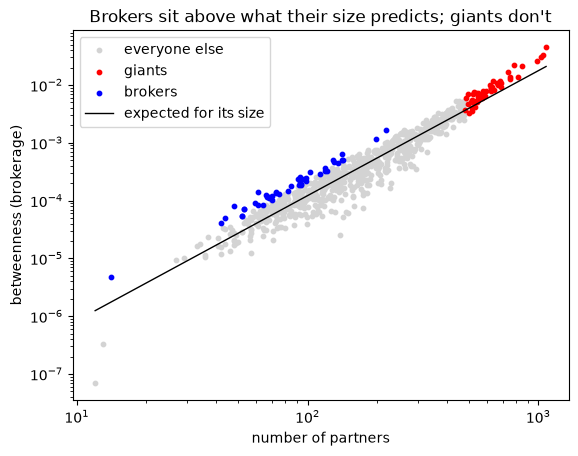

In [70]:
# partners vs brokerage: only organizations that can be brokers (>= 10 projects), giants and brokers highlighted
d = data[(data["betweenness"] > 0) & (data["n_projects"] >= 10)]

for grp, color in [("everyone else", "lightgray"), ("giants", "red"), ("brokers", "blue")]:
    g = d[d["group"] == grp]
    plt.scatter(g["degree"], g["betweenness"], color=color, s=10, label=grp)

# expected betweenness for each size (the broker regression m1); brokers sit furthest above this line
xs = np.linspace(np.log(d["degree"]).min(), np.log(d["degree"]).max(), 50)
plt.plot(np.exp(xs), np.exp(m1.coef()["Intercept"] + m1.coef()["log_degree"] * xs),
         color="black", lw=1, label="expected for its size")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("number of partners")
plt.ylabel("betweenness (brokerage)")
plt.title("Brokers sit above what their size predicts; giants don't")
plt.legend()
plt.show()

**Robustness check**: remove giants first, brokers first, or random organizations
- Core network = only ties with at least 2 shared projects (the lasting collaborations) - robustness check
- On the full network almost nothing falls apart, because it is so dense

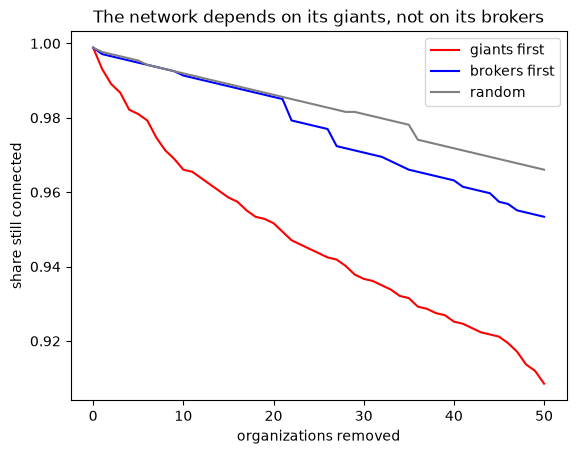

After removing 50: giants 0.909 | brokers 0.953 | random 0.966


In [69]:
core = nx.Graph()
core.add_edges_from((u, v) for u, v, d in org_net.edges(data=True) if d["n_joint"] >= 2)
n = core.number_of_nodes()

def share_after(remove):
    H = core.copy()
    H.remove_nodes_from(remove)
    return len(max(nx.connected_components(H), key=len)) / n

giants_first = sorted(core.nodes(), key=lambda x: cent.loc[x, "degree"], reverse=True)
brokers_first = [o for o in data["residual"].sort_values(ascending=False).dropna().index if o in core]
random_order = list(np.random.default_rng(1).permutation(list(core.nodes())))

steps = range(0, 51)
giants_curve = [share_after(giants_first[:k]) for k in steps]
brokers_curve = [share_after(brokers_first[:k]) for k in steps]
random_curve = [share_after(random_order[:k]) for k in steps]

plt.plot(steps, giants_curve, color="red", label="giants first")
plt.plot(steps, brokers_curve, color="blue", label="brokers first")
plt.plot(steps, random_curve, color="gray", label="random")
plt.xlabel("organizations removed")
plt.ylabel("share still connected")
plt.title("The network depends on its giants, not on its brokers")
plt.legend()
plt.show()

print(f"After removing {50}: giants {giants_curve[-1]:.3f} | brokers {brokers_curve[-1]:.3f} | "
      f"random {random_curve[-1]:.3f}")

**P2.6 Does brokerage go with success?**
- Success = EU funding per project (log), ≥ 10 projects
- model 1: size only, model 2: size + brokerage
- Country fixed effects and country-clustered errors, because EU funding pays salaries, which differ by country

In [73]:
# Does brokerage go with more EU money per project? Main model + other size and brokerage measures
succ = reg[reg["funding_eur"] > 0].copy()
succ["log_funding_per_project"] = np.log(succ["funding_eur"] / succ["n_projects"])

# controls: research organization, average consortium size (coord_share is already in reg)
avg_size = memberships.assign(size=memberships["target"].map(consortium_size)) \
                      .groupby("source")["size"].mean()
succ["log_consortium"] = np.log(succ.index.map(avg_size))
succ["rec"] = (succ["org_type"] == "REC").astype(int)

# other size measures and the broker dummy
succ["log_strength"] = np.log(succ["strength"])
succ["log_eigenvector"] = np.log(succ["eigenvector"])
succ["broker_d"] = succ["broker"].astype(int)

controls = " + coord_share + rec + log_consortium | country"
specs = ["log_degree + residual", "log_strength + residual", "log_eigenvector + residual",
         "log_degree + clustering", "log_degree + broker_d"]
models = [pf.feols("log_funding_per_project ~ " + x + controls, data=succ, vcov={"CRV1": "country"})
          for x in specs]

pf.etable(models, labels={
    "log_funding_per_project": "EU funding per project (log)",
    "log_degree": "Partners (log)", "log_strength": "Strength (log)", "log_eigenvector": "Eigenvector (log)",
    "residual": "Extra betweenness (brokerage)", "clustering": "Clustering", "broker_d": "Broker (top 50)",
    "coord_share": "Share of projects coordinated", "rec": "Research organization",
    "log_consortium": "Average consortium size (log)"})

GT(_tbl_data=   __index_level_0__              __index_level_1__                      0  \
0               coef                 Partners (log)  0.140*** <br> (0.022)   
1               coef  Extra betweenness (brokerage)    -0.019 <br> (0.048)   
2               coef  Share of projects coordinated  1.543*** <br> (0.166)   
3               coef          Research organization    0.194* <br> (0.086)   
4               coef  Average consortium size (log)   -0.304* <br> (0.115)   
5               coef                 Strength (log)                          
6               coef              Eigenvector (log)                          
7               coef                     Clustering                          
8               coef                Broker (top 50)                          
9                 fe                        country                      x   
10             stats                   Observations                    695   
11             stats                             R²                  0.339   

                        1                      2                      3  \
0                                                 0.148*** <br> (0.037)   
1     -0.027 <br> (0.047)    -0.019 <br> (0.045)                          
2   1.508*** <br> (0.161)  1.539*** <br> (0.156)  1.548*** <br> (0.166)   
3     0.175* <br> (0.084)     0.166 <br> (0.084)    0.195* <br> (0.083)   
4     -0.181 <br> (0.106)    -0.158 <br> (0.097)   -0.297* <br> (0.121)   
5   0.129*** <br> (0.020)                                                 
6                          0.127*** <br> (0.021)                          
7                                                    0.079 <br> (0.227)   
8                                                                         
9                       x                      x                      x   
10                    695                    695                    695   
11                  0.347                  0.351                  0.339   

                        4  
0   0.139*** <br> (0.022)  
1                          
2   1.552*** <br> (0.159)  
3     0.197* <br> (0.082)  
4    -0.283* <br> (0.104)  
5                          
6                          
7                          
8      0.013 <br> (0.059)  
9                       x  
10                    695  
11                  0.339  , _body=<great_tables._gt_data.Body object at 0x000001ED5D853380>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label='(3)', column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label='(4)', column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label='(5)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001ED5D87F590>, _spanners=Spanners([SpannerInfo(spanner_id='EU funding per project (log)', spanner_level=1, spanner_label='EU funding per project (log)', spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001ED014404A0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001ED014413D0>, _source_notes=['Significance levels: * p < 0.05, ** p < 0.01, *** p < 0.001. Format of coefficient cell: Coefficient   (Std. Error)'], _footnotes=[

In [79]:
geo = data.join(orgs.set_index("index")[["latitude", "longitude"]])
geo = geo[geo["group"].isin(["giants", "brokers"])]          # only giants and brokers
fig = px.scatter_geo(geo, lat="latitude", lon="longitude", color="group", hover_name="name",
                     scope="europe", color_discrete_map={"giants": "red", "brokers": "blue"},
                     title="Where are the giants and the brokers?")
fig.show()

In [76]:
# Where are giants and brokers? Region counts vs expectation + chi-square test

regions = {"North-West": ["DE", "FR", "BE", "NL", "LU", "AT", "DK", "SE", "FI", "NO", "IE", "UK", "CH", "IS"],
           "South": ["ES", "PT", "IT", "EL", "CY", "MT"]}
r10 = data[data["n_projects"] >= 10].copy()
r10["region"] = "Central-East"
for name, countries in regions.items():
    r10.loc[r10["country"].isin(countries), "region"] = name

region_table = pd.DataFrame({
    "giants": r10[r10["giant"]].groupby("region").size(),
    "brokers": r10[r10["broker"]].groupby("region").size(),
    "expected": (50 * r10["region"].value_counts(normalize=True)).round(1),
}).fillna(0)
print("giants vs brokers differ by region: p =",
      round(chi2_contingency(region_table[["giants", "brokers"]].T.values)[1], 3))
region_table

giants vs brokers differ by region: p = 0.004


,giants,brokers,expected
region,,,
Central-East,2,13,5.1
North-West,35,22,28.9
South,13,15,16.0
